# A tour of the residual stream

What happens inside a language model between the text you type and the word it predicts? This notebook runs a small model, [Qwen2.5-0.5B](https://huggingface.co/Qwen/Qwen2.5-0.5B), on one prompt and looks inside at every step.

**You don't have to run anything.** The output of every cell is saved below, so you can read it top to bottom. To run it yourself and change things, see the [README](README.md).

The parts follow the path a prompt takes through the model:

1. Text becomes tokens
2. Tokens become vectors
3. The residual stream is a grid
4. Actual numbers in one column
5. Each block adds to the stream
6. Where attention looks
7. Changing one token
8. Reading the stream before the model is finished
9. From vector to word

Each part explains what you are about to see, shows real numbers from the model, then says what to notice.

> The "what to notice" commentary was written for the default prompts below. If you change them, the numbers and charts will still be right, but the commentary may no longer fit. Finding out where it stops fitting is a good exercise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from transformers import AutoModelForCausalLM, AutoTokenizer

NAME = "Qwen/Qwen2.5-0.5B"
PROMPT = "The capital of France is"
CONTRAST = "The capital of Spain is"  # same prompt with one token changed (Part 7)
DIMS = 8  # how many of the model's dimensions to print when showing raw numbers
BLOCK_TO_INSPECT = 10  # which block Part 5 takes apart (0-based)

## Setup

### Load the model

The first run downloads the model (about 1 GB). It runs fine without a GPU.

A model like this has four pieces we care about. The attribute names below are specific to Qwen and other Llama-style models in Hugging Face. Other architectures have the same four pieces under different names: GPT-2, for example, calls them `transformer.wte`, `transformer.h`, `transformer.ln_f` and `lm_head`.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(NAME)
# float32 keeps the printed numbers clean. "eager" is the plain, slower
# attention code path; the fast default cannot hand back attention weights,
# which Part 6 needs.
model = AutoModelForCausalLM.from_pretrained(NAME, dtype=torch.float32, attn_implementation="eager")
model.eval()

embed = model.model.embed_tokens  # lookup table: token id -> vector
blocks = model.model.layers  # the transformer blocks
final_norm = model.model.norm  # rescales the last vector before the readout
unembed = model.lm_head  # vector -> one score per vocabulary entry

print(f"{len(blocks)} blocks, {embed.weight.shape[1]} dimensions, {embed.weight.shape[0]:,} vocabulary entries")

24 blocks, 896 dimensions, 151,936 vocabulary entries


### Record what happens inside

Hugging Face can return the residual stream after each block (`output_hidden_states`), but its last entry already has `final_norm` applied. To get every layer in the same raw form, and to see what the two halves of each block contribute, we attach **hooks**: small functions PyTorch calls whenever a module finishes running.

`run(text)` then runs the model once and returns everything we recorded.

In [3]:
captured = {}


def capture(key):
    def hook(module, inputs, output):
        tensor = output[0] if isinstance(output, tuple) else output
        captured[key] = tensor[0]  # [0] drops the batch dimension

    return hook


for i, block in enumerate(blocks):
    block.self_attn.register_forward_hook(capture(("attn", i)))
    block.mlp.register_forward_hook(capture(("mlp", i)))
    block.register_forward_hook(capture(("block", i)))


class Recording:
    """Everything recorded from one run of the model."""


def run(text):
    captured.clear()
    enc = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        out = model(**enc, output_hidden_states=True, output_attentions=True)
    n = len(blocks)
    r = Recording()
    r.ids = enc["input_ids"][0]
    r.tokens = [tokenizer.decode([t]) for t in r.ids]
    # stream[layer, position, dimension]; layer 0 = embeddings
    r.stream = torch.stack([out.hidden_states[0][0]] + [captured[("block", i)] for i in range(n)])
    # the update each half of each block added: [block, position, dimension]
    r.attn = torch.stack([captured[("attn", i)] for i in range(n)])
    r.mlp = torch.stack([captured[("mlp", i)] for i in range(n)])
    # attention[block, head, from_position, to_position]
    r.attention = torch.stack([w[0] for w in out.attentions])
    r.logits = out.logits[0]  # logits[position, vocabulary entry]
    return r


def readout(vector):
    """Turn one residual-stream vector into a score for every vocabulary entry."""
    with torch.no_grad():
        return unembed(final_norm(vector))


# Run both prompts once. Every part below reads from these two recordings.
a = run(PROMPT)
c = run(CONTRAST)
assert len(c.ids) == len(a.ids), "CONTRAST must tokenize to the same length as PROMPT"

n_layers, n_pos, d_model = a.stream.shape[0] - 1, a.stream.shape[1], a.stream.shape[2]
n_heads = a.attention.shape[1]
last = n_pos - 1  # the final position: the one the prediction is read from
labels = [repr(t) for t in a.tokens]
norms = a.stream.norm(dim=-1)  # norms[layer, position]: length of each vector
subject = next(p for p in range(n_pos) if a.ids[p] != c.ids[p])  # where the two prompts differ

print(f"stream: {n_layers + 1} layers x {n_pos} positions x {d_model} dimensions")

stream: 25 layers x 5 positions x 896 dimensions


### Display helpers

These only format numbers and draw charts. Nothing about the model is in here, so feel free to skip this cell.

In [4]:
INK, SECONDARY, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#898781", "#fcfcfb", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 9, "text.color": INK, "axes.labelcolor": SECONDARY, "axes.titlesize": 10,
    "xtick.color": SECONDARY, "ytick.color": SECONDARY, "axes.edgecolor": "#c3c2b7",
})


def fmt(values, width=8):
    """Format a row of numbers for printing."""
    return " ".join(f"{v:{width}.3f}" for v in values.tolist())


def show_grid(ax, values, columns, title, row_name="layer", first_row=0, number="{:.1f}", norm=None, vmin=None, vmax=None):
    """Draw a [rows, columns] tensor as a grid of colored cells, darker = larger."""
    values = values.numpy()
    scale = {"norm": norm} if norm is not None else {"vmin": vmin, "vmax": vmax}
    image = ax.imshow(values, cmap=BLUES, aspect="auto", **scale)
    ax.set_title(title, loc="left", pad=10)
    ax.set_ylabel(row_name)
    ax.xaxis.tick_top()
    ax.set_xticks(range(values.shape[1]), columns)
    ax.set_yticks(range(values.shape[0]), range(first_row, first_row + values.shape[0]))
    ax.set_xticks(np.arange(-0.5, values.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, values.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)  # thin gap between cells
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if number:  # write the value in each cell
        for (row, col), v in np.ndenumerate(values):
            ax.text(col, row, number.format(v), ha="center", va="center", fontsize=8, color="white" if image.norm(v) > 0.55 else INK)
    return image

## Part 1: Text becomes tokens

A model never sees letters. A **tokenizer** chops the text into pieces from a fixed vocabulary and hands the model the id number of each piece.

In [5]:
print(f"Prompt: {PROMPT!r}\n")
for pos, (tok, tid) in enumerate(zip(labels, a.ids.tolist())):
    print(f"position {pos}: {tok:<11} id {tid}")

Prompt: 'The capital of France is'

position 0: 'The'       id 785
position 1: ' capital'  id 6722
position 2: ' of'       id 315
position 3: ' France'   id 9625
position 4: ' is'       id 374


**What to notice**

The space belongs to the token that follows it (`' capital'`, not `'capital'`). From here on the model works with these 5 positions, not with characters.

## Part 2: Tokens become vectors (layer 0)

The model owns a lookup table with one row per vocabulary entry: 151,936 rows of 896 numbers each. Step one is to replace each token id with its row. That gives one vector of 896 numbers per position. This is "layer 0" of the residual stream.

Here are the first 8 of the 896 numbers for each token.

In [6]:
for pos in range(n_pos):
    print(f"{labels[pos]:<11} {fmt(a.stream[0, pos, :DIMS])}")

same = torch.equal(a.stream[0], embed.weight[a.ids])
print(f"\nlayer 0 is exactly the lookup-table rows for these ids: {same}")

'The'         -0.032   -0.002    0.012   -0.016    0.016   -0.030    0.002   -0.016
' capital'    -0.014   -0.015   -0.006    0.004   -0.016   -0.002    0.033    0.012
' of'         -0.004    0.005    0.004   -0.000    0.011   -0.009    0.007   -0.009
' France'      0.009    0.001    0.021   -0.013    0.005    0.007   -0.012   -0.010
' is'         -0.005    0.016   -0.006    0.000   -0.007    0.007   -0.003   -0.003

layer 0 is exactly the lookup-table rows for these ids: True


**What to notice**

No context has been used yet. `' is'` gets this same vector in every sentence ever written. Everything the model works out about *this* sentence has to be added on top by the 24 blocks.

## Part 3: The residual stream is a grid

Picture a grid: one column per token, one row per layer. Every cell holds a vector of 896 numbers. Each block reads a row and produces the next one down. That grid is the **residual stream**: 25 rows x 5 columns x 896 numbers.

We can't show 896 numbers per cell, so here each cell is shrunk to one number: the vector's length (its "norm").

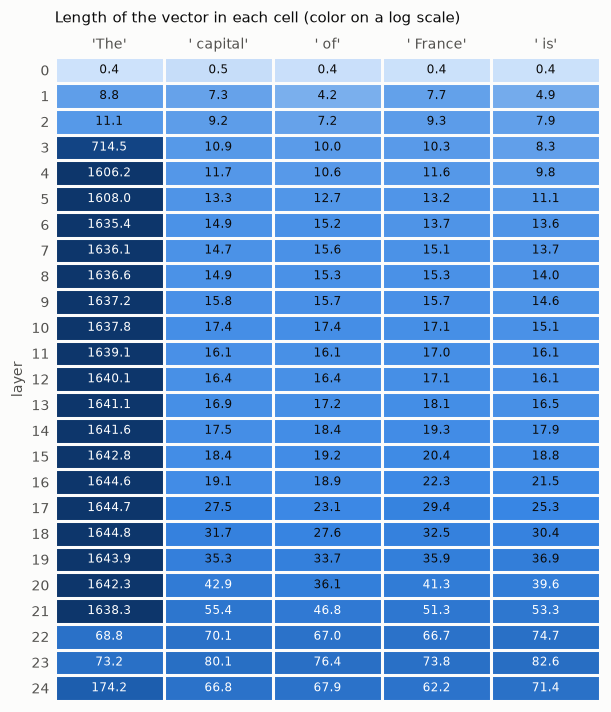

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 7.6))
show_grid(ax, norms, labels, "Length of the vector in each cell (color on a log scale)", norm=LogNorm(norms.min().item(), norms.max().item()))
plt.show()

**What to notice**

1. Every column starts tiny (about 0.4) and grows as blocks add to it.
2. The first column is the odd one: it jumps to about 1,645 and sits there for most of the model. That is a known quirk of these models, not something about the word `'The'`. The usual explanation is that the model parks a giant, nearly constant vector on the first position, and attention rests on it when there is nothing useful to look at. Part 6 checks that. Ignore this column when comparing sizes.

## Part 4: Actual numbers in one column

Now the real contents. This is the **last column** (`' is'`), because that is the vector the model will turn into its prediction. Each row is a layer; each column is one of the first 8 dimensions (out of 896). Read *down* a column to follow one dimension through the model.

In [8]:
print("layer  " + " ".join(f"{'dim ' + str(d):>8}" for d in range(DIMS)))
for layer in range(n_layers + 1):
    print(f"{layer:5d}  {fmt(a.stream[layer, last, :DIMS])}")

print("\nWhich dimensions are biggest, and how much of the vector do they hold?")
for layer in (1, n_layers // 2, n_layers):
    v = a.stream[layer, last]
    top = v.abs().topk(3)
    share = (top.values**2).sum() / (v**2).sum()
    dims = ", ".join(f"dim {i} = {v[i]:.1f}" for i in top.indices.tolist())
    print(f"layer {layer:2d}: {dims}   (top 3 hold {share:.0%} of the squared length)")

layer     dim 0    dim 1    dim 2    dim 3    dim 4    dim 5    dim 6    dim 7
    0    -0.005    0.016   -0.006    0.000   -0.007    0.007   -0.003   -0.003
    1     0.250   -0.131    0.140   -0.023   -0.036    0.049   -0.043   -0.103
    2     0.318   -0.220    0.147    0.089    0.012   -0.006    0.011   -0.104
    3     0.373   -0.157    0.171   -0.142    0.091   -0.080    0.001   -0.174
    4     0.521   -0.118    0.210   -0.208    0.004   -0.037    0.174   -0.241
    5     0.475   -0.329    0.141    0.087    0.115   -0.334    0.211    0.036
    6     0.534   -0.535    0.007   -0.162   -0.326   -0.607    0.063    0.006
    7     0.523   -0.700   -0.110   -0.304    0.192   -0.354    0.348    0.094
    8     0.552   -0.489   -0.339   -0.296    0.064    0.308    0.400    0.018
    9     0.489   -0.513   -0.232   -0.587   -0.018   -0.302    0.599   -0.158
   10     0.357   -0.626   -0.266   -0.482   -0.001   -0.490    0.290   -0.202
   11     0.491   -0.450   -0.250   -0.622    0.175 

**What to notice**

1. Values drift from row to row. No row is a fresh rewrite of the one above it; Part 5 shows why.
2. No column has a readable meaning. There is no "France dimension". Meaning lives in combinations of many dimensions (directions), which is why Parts 7 and 8 compare or decode whole vectors instead.
3. The dimensions are very unequal. The 8 shown here are small ones; just 3 of the 896 hold about a third of the vector, and dim 490 is in the top 3 at all three layers shown.

## Part 5: Each block adds to the stream

A block has two halves:

- **attention** looks at earlier tokens and pulls information from them
- the **MLP** computes on this position's vector alone

Neither one replaces the vector. Each computes an update and *adds* it:

```
after = before + attention_update + mlp_update
```

That is why it is called a "stream": information accumulates in it. Let's check that on one block, at the last token.

In [9]:
b = BLOCK_TO_INSPECT
before, after = a.stream[b, last], a.stream[b + 1, last]
attn_update, mlp_update = a.attn[b, last], a.mlp[b, last]

print(f"Block {b + 1} (takes layer {b} to layer {b + 1}), last token, first {DIMS} dims:\n")
print(f"before (layer {b:2d})   {fmt(before[:DIMS])}")
print(f"+ attention update  {fmt(attn_update[:DIMS])}")
print(f"+ MLP update        {fmt(mlp_update[:DIMS])}")
print(f"= sum               {fmt((before + attn_update + mlp_update)[:DIMS])}")
print(f"after  (layer {b + 1:2d})   {fmt(after[:DIMS])}")

error = (a.stream[:-1] + a.attn + a.mlp - a.stream[1:]).abs().max().item()
print(f"\nlargest mismatch over all {n_layers} blocks, all positions, all dims: {error:.6f}")

Block 11 (takes layer 10 to layer 11), last token, first 8 dims:

before (layer 10)      0.357   -0.626   -0.266   -0.482   -0.001   -0.490    0.290   -0.202
+ attention update     0.051   -0.089   -0.026   -0.005   -0.069    0.364   -0.017   -0.256
+ MLP update           0.083    0.265    0.042   -0.135    0.245   -0.160   -0.186    0.375
= sum                  0.491   -0.450   -0.250   -0.622    0.175   -0.286    0.087   -0.083
after  (layer 11)      0.491   -0.450   -0.250   -0.622    0.175   -0.286    0.087   -0.083

largest mismatch over all 24 blocks, all positions, all dims: 0.000000


The same thing for every block, as sizes: how long is the vector going in, and how long is each update?

In [10]:
print("block   before   attention      MLP")
for i in range(n_layers):
    print(f"{i + 1:5d} {norms[i, last]:8.1f} {a.attn[i, last].norm():11.1f} {a.mlp[i, last].norm():8.1f}")
print(f"\nlength after the last block: {norms[-1, last]:.1f}")

block   before   attention      MLP
    1      0.4         0.4      4.9
    2      4.9         2.8      2.9
    3      7.9         1.7      3.0
    4      8.3         2.4      3.8
    5      9.8         3.7      4.6
    6     11.1         3.8      6.2
    7     13.6         2.2      5.5
    8     13.7         3.2      5.7
    9     14.0         4.0      5.0
   10     14.6         2.4      5.1
   11     15.1         4.3      5.7
   12     16.1         2.8      5.8
   13     16.1         3.1      5.7
   14     16.5         2.3      6.7
   15     17.9         3.6      5.8
   16     18.8         4.6      8.7
   17     21.5         1.6     10.3
   18     25.3         4.9      8.7
   19     30.4         4.7     11.9
   20     36.9         4.2     12.2
   21     39.6         8.5     21.4
   22     53.3        13.1     29.1
   23     74.7         4.0     24.7
   24     82.6        10.3     67.4

length after the last block: 71.4


**What to notice**

1. "sum" and "after" match exactly, and the mismatch over the whole grid is zero. The stream really is just a running total of updates.
2. After block 1, each update is smaller than the vector it is added to. A block nudges the stream; it does not replace it.
3. At this position the MLP update is larger than the attention update in every block.
4. The last block adds an update of length 67.4 to a vector of length 82.6, and the result is *shorter* (71.4). Adding can also cancel: the only way to remove something from the stream is to add its opposite.

## Part 6: Where attention looks

Attention is the only way information moves between columns. In each block, every position splits 100% of its attention across itself and the positions to its left, and pulls in information in that proportion. A block does this 14 times in parallel ("heads"), each with its own pattern.

Two views of where the **last token** (`' is'`) looks:

- **Left:** each block's attention, averaged over its 14 heads.
- **Right:** how much each individual head looks at `' France'`.

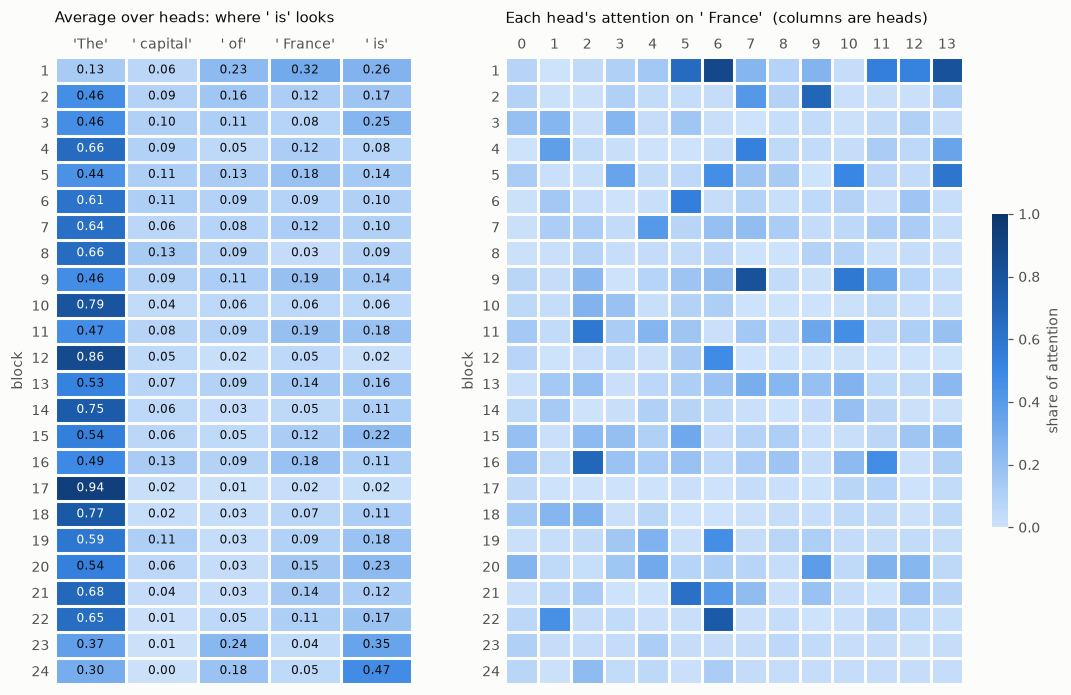

The first token gets the largest average share in 22 of 24 blocks (57% on average).
' France' gets 11% on average. The heads that look at it hardest:
  block 1, head 6: 0.88
  block 1, head 13: 0.82
  block 9, head 7: 0.81


In [11]:
weights = a.attention[:, :, last]  # [block, head, to_position] for the last token
mean = weights.mean(dim=1)  # average over heads
on_subject = weights[:, :, subject]  # [block, head]: each head's attention on ' France'

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 7.4), width_ratios=[5, 8])
show_grid(left, mean, labels, "Average over heads: where ' is' looks", row_name="block", first_row=1, number="{:.2f}", vmin=0, vmax=1)
image = show_grid(right, on_subject, range(n_heads), f"Each head's attention on {labels[subject]}  (columns are heads)", row_name="block", first_row=1, number=None, vmin=0, vmax=1)
fig.colorbar(image, ax=right, shrink=0.5, label="share of attention").outline.set_visible(False)
plt.show()

print(f"The first token gets the largest average share in {int((mean.argmax(dim=1) == 0).sum())} of {n_layers} blocks ({mean[:, 0].mean():.0%} on average).")
print(f"{labels[subject]} gets {mean[:, subject].mean():.0%} on average. The heads that look at it hardest:")
for flat in on_subject.flatten().topk(3).indices.tolist():
    block_index, head = divmod(flat, n_heads)
    print(f"  block {block_index + 1}, head {head}: {on_subject[block_index, head]:.2f}")

**What to notice**

1. Each row of the left chart adds up to 1. Attention is a budget, not a set of independent dials.
2. The first token takes the biggest share in 22 of 24 blocks, 57% on average, even though `'The'` says nothing about the question. This is the resting place from Part 3: a head with nothing to find parks there.
3. Averages hide specialists. `' France'` gets only 11% on average, so its column on the left is pale. But the right chart has a few dark cells: single heads that put most of their attention on it (0.88, 0.82 and 0.81 for the top three, printed above). Heads like these are the candidates for carrying the country into this column. Proving which ones matter takes an experiment (switch a head off and see if the answer changes), not a chart.

## Part 7: Changing one token

Now compare our prompt with one that differs in a single token:

- **A:** `The capital of France is`
- **B:** `The capital of Spain is`

Both grids are compared cell by cell using **cosine similarity**: 1.000 means the two vectors point the same way, 0 means unrelated. Column headers are prompt A's tokens; `' France'` is the one that differs.

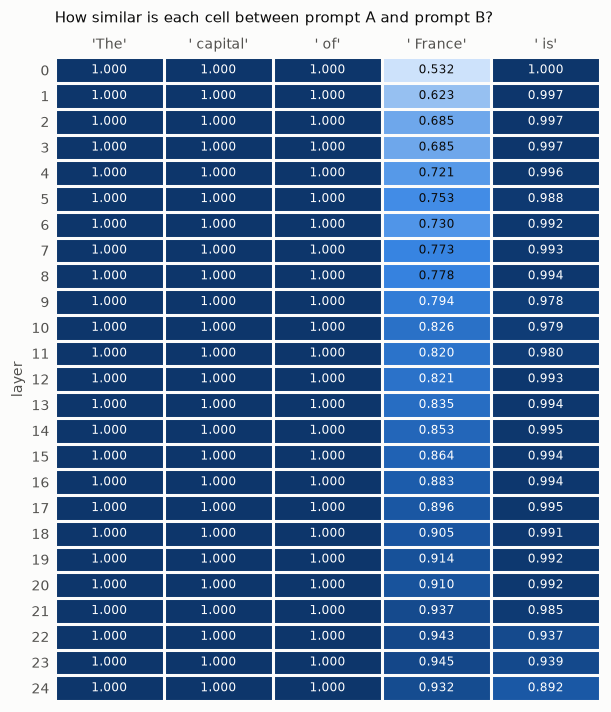

largest difference anywhere in the columns left of the change: 0.000000


In [12]:
cos = torch.cosine_similarity(a.stream, c.stream, dim=-1)

fig, ax = plt.subplots(figsize=(6.4, 7.6))
show_grid(ax, cos, labels, "How similar is each cell between prompt A and prompt B?", number="{:.3f}", vmin=cos.min().item(), vmax=1)
plt.show()

left_diff = (a.stream[:, :subject] - c.stream[:, :subject]).abs().max().item()
print(f"largest difference anywhere in the columns left of the change: {left_diff:.6f}")

**What to notice**

1. Columns to the left of the changed token are identical at every layer. A position can only look at itself and what is to its left (Part 6), so nothing about the country can ever reach them.
2. The changed column starts far apart (0.53: two different words) and gets *more* alike going down. The model is building up what the two have in common: a country, in a sentence asking for a capital.
3. The last column starts at exactly 1.000: same token, same lookup row. It only knows which country it is about because attention copied that in from the left. It stays close to 1 for most of the model, then drops in the final few layers (0.89 at the end). Compare that with where the answer shows up in Part 8.

## Part 8: Reading the stream before the model is finished

Only the last row is ever turned into a prediction. But we can apply that same readout to earlier rows and ask: "if the model stopped here, what would it say?" This trick is called the **logit lens**.

One caveat: the readout was trained to read the last row only. Early rows are not written in its "language", so the top token there is noise, not a thought.

The table shows the top token at each layer for prompt A, then the probability and rank (out of 151,936) of each prompt's final answer.

In [13]:
answer_a = a.logits[last].argmax().item()
answer_c = c.logits[last].argmax().item()
name_a, name_c = repr(tokenizer.decode([answer_a])), repr(tokenizer.decode([answer_c]))

lens = {"a": {"prob": [], "rank": []}, "c": {"prob": [], "rank": []}}
print(f"layer  {'top token (A)':<16} {'P(' + name_a + ')':>12} {'rank':>7}   {'P(' + name_c + ')':>12} {'rank':>7}")
for layer in range(n_layers + 1):
    for key, recording, answer in (("a", a, answer_a), ("c", c, answer_c)):
        scores = readout(recording.stream[layer, last])
        lens[key]["prob"].append(scores.softmax(-1)[answer].item())
        lens[key]["rank"].append(int((scores > scores[answer]).sum().item()) + 1)
        if key == "a":
            top_token = repr(tokenizer.decode([scores.argmax().item()]))
    print(f"{layer:5d}  {top_token:<16} {lens['a']['prob'][-1]:12.4f} {lens['a']['rank'][-1]:7d}   {lens['c']['prob'][-1]:12.4f} {lens['c']['rank'][-1]:7d}")

layer  top token (A)     P(' Paris')    rank   P(' Madrid')    rank
    0  ' is'                  0.0000    4609         0.0000   20852
    1  '\';";\n'              0.0000    3915         0.0000    7710
    2  ".','"                 0.0000   18015         0.0000   42838
    3  ".','"                 0.0000   44525         0.0000   78260
    4  ".','"                 0.0000   34940         0.0000   34294
    5  ".','"                 0.0000   36167         0.0000   32526
    6  '\';";\n'              0.0000   53921         0.0000   99043
    7  'апр'                  0.0000   43922         0.0000   92009
    8  'апр'                  0.0000   33039         0.0000   96059
    9  '.toFloat'             0.0000   26567         0.0000   83190
   10  '\';";\n'              0.0000   32480         0.0000   91996
   11  '\';";\n'              0.0000   35174         0.0000   81721
   12  '\';";\n'              0.0000   37809         0.0000   49375
   13  'уницип'               0.0000   32795    

The same two answers as charts. Rank is on a log scale with first place at the top.

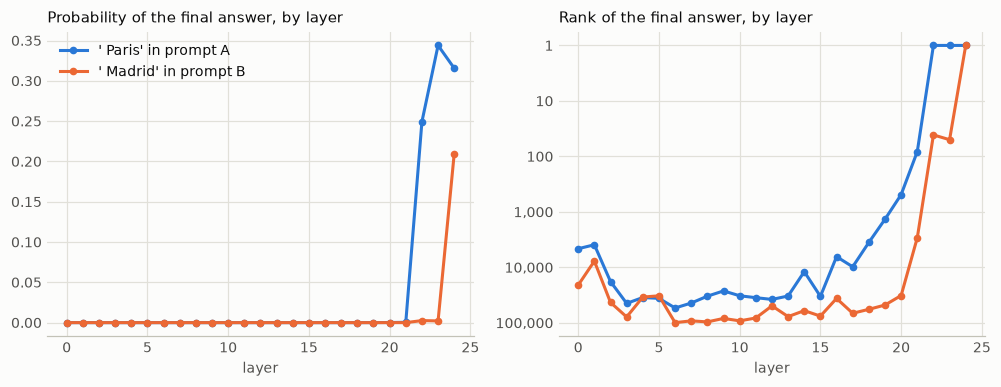

In [14]:
fig, (ax_prob, ax_rank) = plt.subplots(1, 2, figsize=(11, 3.6))
series = (("a", f"{name_a} in prompt A", BLUE), ("c", f"{name_c} in prompt B", ORANGE))
for key, label, color in series:
    ax_prob.plot(lens[key]["prob"], color=color, linewidth=2, marker="o", markersize=4, label=label)
    ax_rank.plot(lens[key]["rank"], color=color, linewidth=2, marker="o", markersize=4, label=label)
ax_prob.set_title("Probability of the final answer, by layer", loc="left")
ax_rank.set_title("Rank of the final answer, by layer", loc="left")
ax_rank.set_yscale("log")
ax_rank.invert_yaxis()
ax_rank.yaxis.set_major_formatter(lambda value, _: f"{int(value):,}")
for ax in (ax_prob, ax_rank):
    ax.set_xlabel("layer")
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(which="both", length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
ax_prob.legend(frameon=False, loc="upper left")
plt.show()

**What to notice**

1. Layer 0 reads back `' is'`: the embedding of a token decodes to itself. Then noise for the first half of the model, as the caveat said.
2. The answer does not appear suddenly. Watch the Paris rank: it falls from the tens of thousands at layer 15 to 82 at layer 21, before taking first place at 22. The top token alone hides that build-up. Madrid follows the same shape a little later and only wins at the last layer.
3. Most of layers 16-21 decode to blanks like `' ____'`. Part 9 shows blanks are a real competitor in the final answer too: this model has read a lot of quiz worksheets ("The capital of France is ____"). A reading, not a proven fact: the middle layers settle on "an answer goes here" before the last layers work out which answer.
4. Both prompts are identical in this column at layer 0 and end up at different cities. That difference arrived through attention.

## Part 9: From vector to word, then do it again

The last step turns the bottom-right cell of the grid into a prediction: 896 numbers become one score per vocabulary entry, and the scores become probabilities.

To write more than one token, the model appends its choice to the prompt and runs the whole thing again. Two steps of that:

In [15]:
text, previous = PROMPT, None
for step in (1, 2):
    recording = run(text)
    top = recording.logits[-1].softmax(-1).topk(5)
    print(f"step {step}: input = {text!r}")
    for p, t in zip(top.values.tolist(), top.indices.tolist()):
        print(f"    {p:7.1%}  {tokenizer.decode([t])!r}")
    if previous is not None:
        shared = previous.stream.shape[1]
        drift = (recording.stream[:, :shared] - previous.stream).abs().max().item()
        print(f"\nlargest change in the first {shared} columns after adding a token: {drift:.6f}")
    previous = recording
    text += tokenizer.decode([top.indices[0].item()])

print(f"\nresult: {text!r}")

step 1: input = 'The capital of France is'
      31.6%  ' Paris'
      11.5%  ' ______'
       6.4%  ' ____'
       5.5%  ' __'
       5.1%  ':\n'
step 2: input = 'The capital of France is Paris'
      46.5%  '.'
      22.1%  ','
       9.9%  '.\n'
       5.7%  ' and'
       4.1%  '.\n\n'

largest change in the first 5 columns after adding a token: 0.000042

result: 'The capital of France is Paris.'


**What to notice**

1. The output is a probability for every vocabulary entry, not one answer. Here we always took the top one; chat apps usually sample from the list.
2. This is a "base" model: it continues text, it does not answer questions. That is why quiz-style blanks get a real share.
3. Adding a token left the first 5 columns unchanged (the tiny number is rounding noise). Same rule as Part 7: nothing to the right can affect them. Real systems use this to avoid recomputing old columns.

## Things to try

The settings are in the first code cell. Change one, then re-run the whole notebook. If you change `PROMPT`, change `CONTRAST` to match: the two must have the same number of tokens.

1. **Change the contrast country.** Set `CONTRAST = "The capital of Japan is"`. The model's top guess is no longer a city. What is it, and what does Part 8 look like now?
2. **Get rid of the blanks.** Give the model an example first: `"The capital of Italy is Rome. The capital of France is"` (and the same with Spain for `CONTRAST`). Compare Part 9.
3. **Take apart a different block.** Change `BLOCK_TO_INSPECT` to `0` or `23` and compare Part 5.
4. **Find a prompt it gets wrong.** Does the right answer still show up in the middle layers of Part 8?
5. **Harder: test a claim.** Part 6 names attention heads that look hard at `' France'`. Switch one off and see whether the prediction changes.

The [README](README.md) lists where to go next for real experiments.